In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import python_anesthesia_simulator as pas

In [ ]:
pd.read_csv('data/database.csv').columns

Index(['Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'Time', 'caseid', 'BIS',
       'SQI', 'Propofol', 'Remifentanil', 'MAP', 'SAP', 'DAP', 'NI_MAP',
       'NI_SAP', 'NI_DAP', 'HR', 'Vol_Rem', 'Vol_Prop', 'RR', 'SV', 'age',
       'sex', 'weight', 'height', 'bmi', 'opstart', 'intubation_time',
       'approach', 'bis_base', 'hr_base', 'map_base', 'sv_base', 'split'],
      dtype='object')

In [15]:
# Load data
data_simu = pd.read_csv('data/simulated_vitaldb_no_stimuli.csv')
data_measure = pd.read_csv('data/database.csv')
data = pd.merge(data_simu, data_measure, on=['caseid', 'Time'], suffixes=("_sim", "_meas"))
print(f"Number of case: {data.caseid.nunique()}")
print(f"mean BIS value: {data['BIS_meas'].median():.2f}")


Number of case: 98
mean BIS value: 42.32


In [16]:
available_bis_model = [
    'Eleveld',
    'Bouillon',
    'Vanluchene',
    'Fuentes',
    'Yumuk',
    ]
for model in available_bis_model:
    bis = []
    for caseid, data_case in data.groupby('caseid'):
        bis_model = pas.BIS_model(hill_model=model, age=data_case['age'].iloc[0])
        e0_init = bis_model.E0
        bis_model.E0 = data_case['BIS_meas'].iloc[0]
        bis_model.Emax *= bis_model.E0 / e0_init
        bis_case = bis_model.compute_bis(data_case['x_propo_4'].values, data_case['x_remi_4'].values)
        bis+=list(bis_case)
    data.insert(0, f"BIS_{model}", bis)

bis = []
model='Bouillon'
for caseid, data_case in data.groupby('caseid'):
    bis_model = pas.BIS_model(hill_model=model, age=data_case['age'].iloc[0])
    e0_init = bis_model.E0
    bis_model.E0 = data_case['BIS_meas'].iloc[0]
    bis_model.Emax *= bis_model.E0 / e0_init
    bis_case = bis_model.compute_bis(data_case['x_propo_4'].values, data_case['x_remi_4'].values)
    bis+=list(bis_case)
data.insert(0, "BIS_Bouillon_E0", bis)

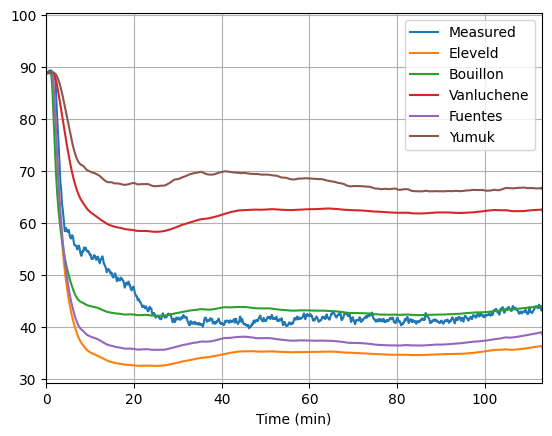

In [17]:
min_case_duration = data.groupby('caseid')['Time'].max().min()

data['Time'] = data.groupby('caseid')['Time'].transform(lambda x: x - x.min())
intub_median = np.median(data['intubation_time'].unique())
opstart_median = np.median(data['opstart'].unique())
bis_mean = data.groupby("Time")["BIS_meas"].mean()
bis_std = data.groupby("Time")["BIS_meas"].std()
x = bis_mean.index/60
plt.plot(x, bis_mean, label='Measured')
for model in available_bis_model:
    bis_mean = data.groupby("Time")[f"BIS_{model}"].mean().values
    plt.plot(x, bis_mean, label=model)
# plt.plot(x, data.groupby("Time")["BIS_Bouillon_E0"].mean().values, label='Bouillon (E0 identified)', linestyle='--', color='green')

plt.grid()
plt.legend(prop={'size': 10}, loc=1)
plt.xlim([0,min_case_duration/60])
plt.xlabel('Time (min)')
plt.savefig('output/bis_comparison.pdf', dpi=300)
plt.show()

In [18]:
mdpe_model = {}
mdape_model = {}
available_bis_model.append('Bouillon_E0')
for model in available_bis_model:
    mdpe_model_list = []
    mdape_model_list = []
    length_list = []

    for caseid, data_case in data.groupby('caseid'):
        PE = 100 * ((data_case['BIS_meas'] - data_case[f"BIS_{model}"])/data_case['BIS_meas']).values
        MDPE_case = np.median(PE)
        MDAPE_case = np.median(np.abs(PE))
        var_mdpe_case = np.var(PE)
        mdpe_model_list.append(MDPE_case)
        mdape_model_list.append(MDAPE_case)
        length_list.append(len(PE))
    
    MDPE_model = np.sum(np.multiply(mdpe_model_list,length_list)) / np.sum(length_list)
    MDAPE_model = np.sum(np.multiply(mdape_model_list,length_list)) / np.sum(length_list)
    mdpe_model[model] = MDPE_model
    mdape_model[model] = MDAPE_model
print(mdpe_model)
print(mdape_model)

{'Eleveld': np.float64(14.538462548484343), 'Bouillon': np.float64(-3.015928874834061), 'Vanluchene': np.float64(-48.27027483383199), 'Fuentes': np.float64(9.611047165426694), 'Yumuk': np.float64(-60.39764545042989), 'Bouillon_E0': np.float64(-3.015928874834061)}
{'Eleveld': np.float64(24.674595696951314), 'Bouillon': np.float64(19.357427929006715), 'Vanluchene': np.float64(50.05967844275882), 'Fuentes': np.float64(21.20607482165377), 'Yumuk': np.float64(63.127504556018714), 'Bouillon_E0': np.float64(19.357427929006715)}
